# Synthetic corpus EDA

Explore the dated-corpus shapes and answerability on synthetic data before real MultiClaim data lands.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from temporal_fact_checked_retrieval_eval.plotting import apply_style

from temporal_fact_checked_retrieval_eval.dataset import (
    DatedCorpus,
    FactCheck,
    GoldPair,
    Post,
    earliest_time,
)
from temporal_fact_checked_retrieval_eval.dataset.synthetic import make_synthetic_corpus
from temporal_fact_checked_retrieval_eval.protocols import (
    answerable,
    answerable_rate,
    build_causal_pool,
    build_size_matched_pool,
)

apply_style()

In [2]:
corpus = make_synthetic_corpus(seed=0)

In [3]:
rows = [{"language": "all", "answerable_rate": answerable_rate(corpus)}]

for lang in sorted({post.language for post in corpus.posts.values()}):
    lang_pairs = [
        pair for pair in corpus.pairs
        if corpus.posts[pair.post_id].language == lang
    ]
    rate = (
        sum(answerable(corpus, pair) for pair in lang_pairs) / len(lang_pairs)
        if lang_pairs
        else 0.0
    )
    rows.append({"language": lang, "answerable_rate": rate})

rates = pd.DataFrame(rows).set_index("language")
print(rates)

          answerable_rate
language                 
all              0.370000
en               0.314286
pl               0.431579


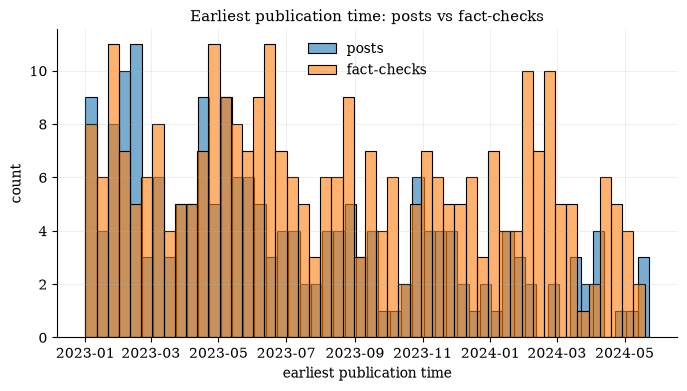

In [4]:
post_times = pd.to_datetime(
    [earliest_time(post.instances) for post in corpus.posts.values()],
    errors="coerce",
).dropna()
fact_check_times = pd.to_datetime(
    [earliest_time(fc.instances) for fc in corpus.fact_checks.values()],
    errors="coerce",
).dropna()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(post_times, bins=50, label="posts", alpha=0.6, ax=ax)
sns.histplot(fact_check_times, bins=50, label="fact-checks", alpha=0.6, ax=ax)
ax.set_xlabel("earliest publication time")
ax.set_ylabel("count")
ax.set_title("Earliest publication time: posts vs fact-checks")
ax.legend()
plt.show(block=False)

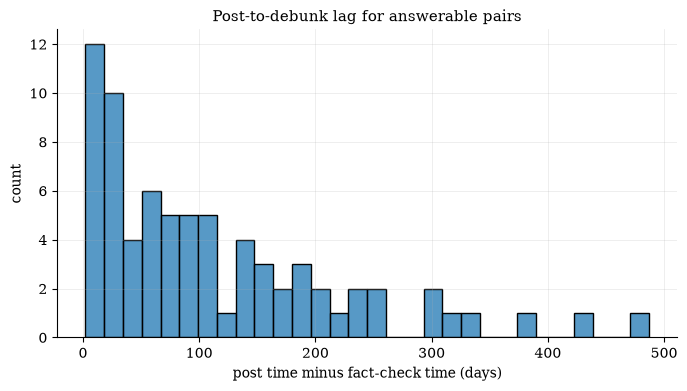

In [5]:
lags = []
for pair in corpus.pairs:
    if not answerable(corpus, pair):
        continue
    post_time = earliest_time(corpus.posts[pair.post_id].instances)
    fact_check_time = earliest_time(corpus.fact_checks[pair.fact_check_id].instances)
    lags.append((post_time - fact_check_time).days)

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(lags, bins=30, ax=ax)
ax.set_xlabel("post time minus fact-check time (days)")
ax.set_ylabel("count")
ax.set_title("Post-to-debunk lag for answerable pairs")
plt.show(block=False)

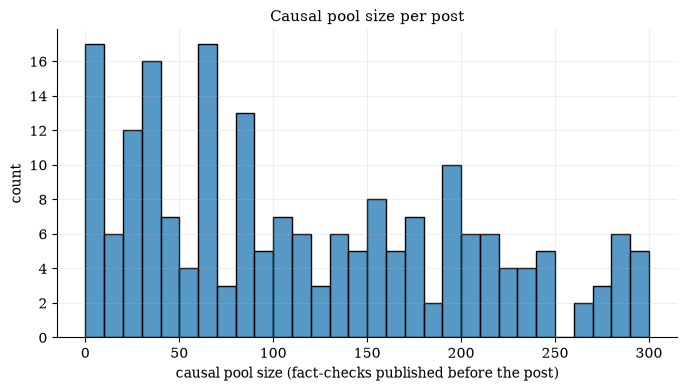

In [6]:
pool_sizes = [len(build_causal_pool(corpus, post)) for post in corpus.posts.values()]

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(pool_sizes, bins=30, ax=ax)
ax.set_xlabel("causal pool size (fact-checks published before the post)")
ax.set_ylabel("count")
ax.set_title("Causal pool size per post")
plt.show(block=False)

Real MultiClaim data replaces the synthetic corpus through the loader, with no protocol changes.